# Anomaly detection in N-CMAPSS with PCA and an autoencoder

The NASA N-CMAPSS dataset contains **simulated turbofan-engine measurements** generated with a high-fidelity physics-based model.

Each engine starts in a healthy condition and gradually degrades. In contrast to an abrupt fault, gradual degradation is better described by a **continuous anomaly score** than by only a binary normal/abnormal decision. The score can later be converted into a health index.

In this notebook, we compare two reconstruction models:

1. Principal component analysis (PCA)
2. An autoencoder (AE)

Both models are trained only on healthy data.

# 1. Load the dataset

One row corresponds to one measurement instant.

The dataset contains:

- `U`: engine unit
- `C`: flight cycle
- `W`: operating conditions or commands
- `Xs`: sensor responses

The operating conditions and sensor values are physically related. Here we first treat their combined measurement vector as generic multivariate data. At the end, we return to the question of whether this is the most informative formulation.

## The N-CMAPSS variables

The dataset consists of **operating conditions** and **sensor measurements** of a turbofan engine.

The operating conditions describe **how the engine is operated**, while the sensors measure **how the engine responds**.

### Operating conditions (inputs)

| Variable | Description |
|----------|-------------|
| **alt** | Flight altitude |
| **Mach** | Aircraft Mach number (speed relative to the speed of sound) |
| **TRA** | Throttle Resolver Angle (pilot throttle setting) |
| **T2** | Ambient inlet air temperature |

The operating conditions define the engine's operating point. For example, an engine behaves differently during take-off than during cruise because the throttle setting, altitude and ambient conditions are different.

### Sensor measurements (responses)

| Variable | Description |
|----------|-------------|
| **T24, T30, T40, T48, T50** | Temperatures measured at different stages of the engine |
| **P15, P2, P21, P24, Ps30, P30, P40, P50** | Pressures measured at different engine stations |
| **Nf** | Fan rotational speed |
| **Nc** | Core compressor rotational speed |
| **Wf** | Fuel flow rate |

The sensor values are **strongly coupled** through the engine's thermodynamic processes. Changing the operating conditions (e.g., increasing the throttle) affects many sensor values simultaneously, even when the engine is perfectly healthy.

In this notebook we treat the complete measurement vector as the input to a reconstruction model. In the next notebook we will exploit the physical **input–output relationship** by predicting the sensor responses from the operating conditions.

In [ ]:

!pip -q install gdown

In [ ]:
import h5py
import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_recall_curve, average_precision_score

import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
file_id = "1-b0D-vzPKBWeD1J7tezDeyom6Ia0A3uz"
gdown.download(
    f"https://drive.google.com/uc?id={file_id}",
    "data.h5",
    quiet=False,
)

Downloading...
From (original): https://drive.google.com/uc?id=1-b0D-vzPKBWeD1J7tezDeyom6Ia0A3uz
From (redirected): https://drive.google.com/uc?id=1-b0D-vzPKBWeD1J7tezDeyom6Ia0A3uz&confirm=t&uuid=725e26fd-401c-47af-9c70-f57d3cbfdbd5
To: /content/data.h5
100%|██████████| 438M/438M [00:08<00:00, 54.4MB/s]


'data.h5'

## Development and test engines

The N-CMAPSS dataset contains measurements from several **simulated turbofan engines**. Each engine experiences a different degradation trajectory and eventually fails.

The engines are divided into two groups:

- **Development engines** are used to develop the anomaly detection model. They correspond to the "training set" as well as the "validation set" used for hyperparamters tuning in machine learning.
- **Test engines** are kept completely separate and are used only to evaluate how well the trained model detects degradation on previously unseen engines.

In this notebook we use only a subset of the development engines (16, 18 and 20). Furthermore, we assume that only the **first 20 flight cycles** of these engines correspond to healthy operation. These measurements are used to train the reconstruction models.

The test engines (11, 14 and 15) contain complete degradation trajectories. During evaluation, the anomaly score should remain low while the engine is healthy and increase as degradation develops.

> **Important:** The fault onset of the test engines is used **only for evaluating** the anomaly detector. The PCA and autoencoder are trained exclusively on healthy measurements and never see these labels during training.

In [ ]:
with h5py.File("data.h5", "r") as hdf:
    W_dev = np.array(hdf["W_train"])
    Xs_dev = np.array(hdf["X_s_train"])
    U_dev = np.array(hdf["U_train"]).ravel()
    C_dev = np.array(hdf["C_train"]).ravel()

    W_test = np.array(hdf["W_test"])
    Xs_test = np.array(hdf["X_s_test"])
    U_test = np.array(hdf["U_test"]).ravel()
    C_test = np.array(hdf["C_test"]).ravel()

W_names = ["alt", "Mach", "TRA", "T2"]

Xs_names = [
    "T24", "T30", "T40", "T48", "T50",
    "P15", "P2", "P21", "P24", "Ps30", "P30", "P40", "P50",
    "Nf", "Nc", "Wf",
]

feature_names = W_names + Xs_names

print("Development data:", W_dev.shape, Xs_dev.shape)
print("Test data:       ", W_test.shape, Xs_test.shape)
print("Development engines:", np.unique(U_dev))
print("Test engines:       ", np.unique(U_test))

Development data: (526347, 4) (526347, 16)
Test data:        (125375, 4) (125375, 16)
Development engines: [ 2  5 10 16 18 20]
Test engines:        [11 14 15]


### Variable groups

The operating conditions describe how the engine is commanded or operated. The sensors measure the engine response.

In [ ]:
feature_units = {
    "alt": "ft",
    "Mach": "-",
    "TRA": "%",
    "T2": "°R",
    "T24": "°R",
    "T30": "°R",
    "T40": "°R",
    "T48": "°R",
    "T50": "°R",
    "P15": "psia",
    "P2": "psia",
    "P21": "psia",
    "P24": "psia",
    "Ps30": "psia",
    "P30": "psia",
    "P40": "psia",
    "P50": "psia",
    "Nf": "rpm",
    "Nc": "rpm",
    "Wf": "pps",
}

In [ ]:
variable_table = pd.DataFrame({
    "Group": (
        ["Operating condition"] * len(W_names)
        + ["Sensor response"] * len(Xs_names)
    ),
    "Variable": feature_names,
    "Description": [
        "Altitude",
        "Flight Mach number",
        "Throttle-resolver angle",
        "Total temperature at fan inlet",
        "Total temperature at LPC outlet",
        "Total temperature at HPC outlet",
        "Total temperature at burner outlet",
        "Total temperature at HPT outlet",
        "Total temperature at LPT outlet",
        "Total pressure in bypass duct",
        "Total pressure at fan inlet",
        "Total pressure at fan outlet",
        "Total pressure at LPC outlet",
        "Static pressure at HPC outlet",
        "Total pressure at HPC outlet",
        "Total pressure at burner outlet",
        "Total pressure at LPT outlet",
        "Physical fan speed",
        "Physical core speed",
        "Fuel flow",
    ],
    "Unit": [feature_units[name] for name in feature_names],
})

variable_table

,Group,Variable,Description,Unit
0,Operating condition,alt,Altitude,ft
1,Operating condition,Mach,Flight Mach number,-
2,Operating condition,TRA,Throttle-resolver angle,%
3,Operating condition,T2,Total temperature at fan inlet,°R
4,Sensor response,T24,Total temperature at LPC outlet,°R
5,Sensor response,T30,Total temperature at HPC outlet,°R
6,Sensor response,T40,Total temperature at burner outlet,°R
7,Sensor response,T48,Total temperature at HPT outlet,°R
8,Sensor response,T50,Total temperature at LPT outlet,°R
9,Sensor response,P15,Total pressure in bypass duct,psia


## Explore the raw data

Before preprocessing or aggregating the data, we first inspect the original measurements.

This is important because automatic preprocessing can hide important properties of a dataset, such as:

- different numerical scales,
- variation within each flight cycle,
- abrupt changes caused by changing operating conditions,
- relationships between variables,
- unusual or potentially erroneous measurements.

We first examine several consecutive flight cycles of one engine. The values shown below are the original, unscaled measurements.

In [ ]:
# Combine the metadata, operating conditions and sensor measurements
# into one DataFrame. No scaling or aggregation is applied here.

test_raw = pd.DataFrame(
    np.concatenate([W_test, Xs_test], axis=1),
    columns=feature_names,
)

test_raw.insert(0, "cycle", C_test.astype(int))
test_raw.insert(0, "unit", U_test.astype(int))

test_raw.head()

,unit,cycle,alt,Mach,TRA,T2,T24,T30,T40,T48,...,P2,P21,P24,Ps30,P30,P40,P50,Nf,Nc,Wf
0,11,1,-0.998961,-0.187893,0.676269,0.829199,0.768628,0.780609,0.829589,0.812512,...,0.840821,0.816353,0.775308,0.733788,0.734979,0.735217,0.880179,0.754203,0.783265,0.691224
1,11,1,-0.992809,-0.180967,0.676269,0.826158,0.761421,0.774107,0.828739,0.810757,...,0.833849,0.808269,0.767485,0.728297,0.731118,0.729360,0.870859,0.751501,0.786615,0.686263
2,11,1,-0.986178,-0.174041,0.681756,0.822645,0.764514,0.776247,0.828701,0.812012,...,0.826867,0.803923,0.762182,0.726605,0.726965,0.727347,0.863851,0.757431,0.784521,0.685113
3,11,1,-0.979227,-0.172759,0.684499,0.816052,0.755258,0.773020,0.830550,0.812251,...,0.818075,0.794476,0.757063,0.720712,0.722270,0.721999,0.856946,0.754316,0.788763,0.680268
4,11,1,-0.971876,-0.171733,0.681756,0.808882,0.746996,0.767847,0.824393,0.809600,...,0.807939,0.785051,0.745613,0.711386,0.712172,0.712628,0.846448,0.753735,0.770269,0.671740


## raw variables over several cycles

In [ ]:
# Select several consecutive cycles from one engine
unit_to_plot = 11
cycles_to_plot = [1, 2, 3, 4, 5]

raw_subset = test_raw[
    (test_raw["unit"] == unit_to_plot)
    & (test_raw["cycle"].isin(cycles_to_plot))
].copy()

# A continuous sample index makes the temporal order visible.
raw_subset = raw_subset.reset_index(drop=True)



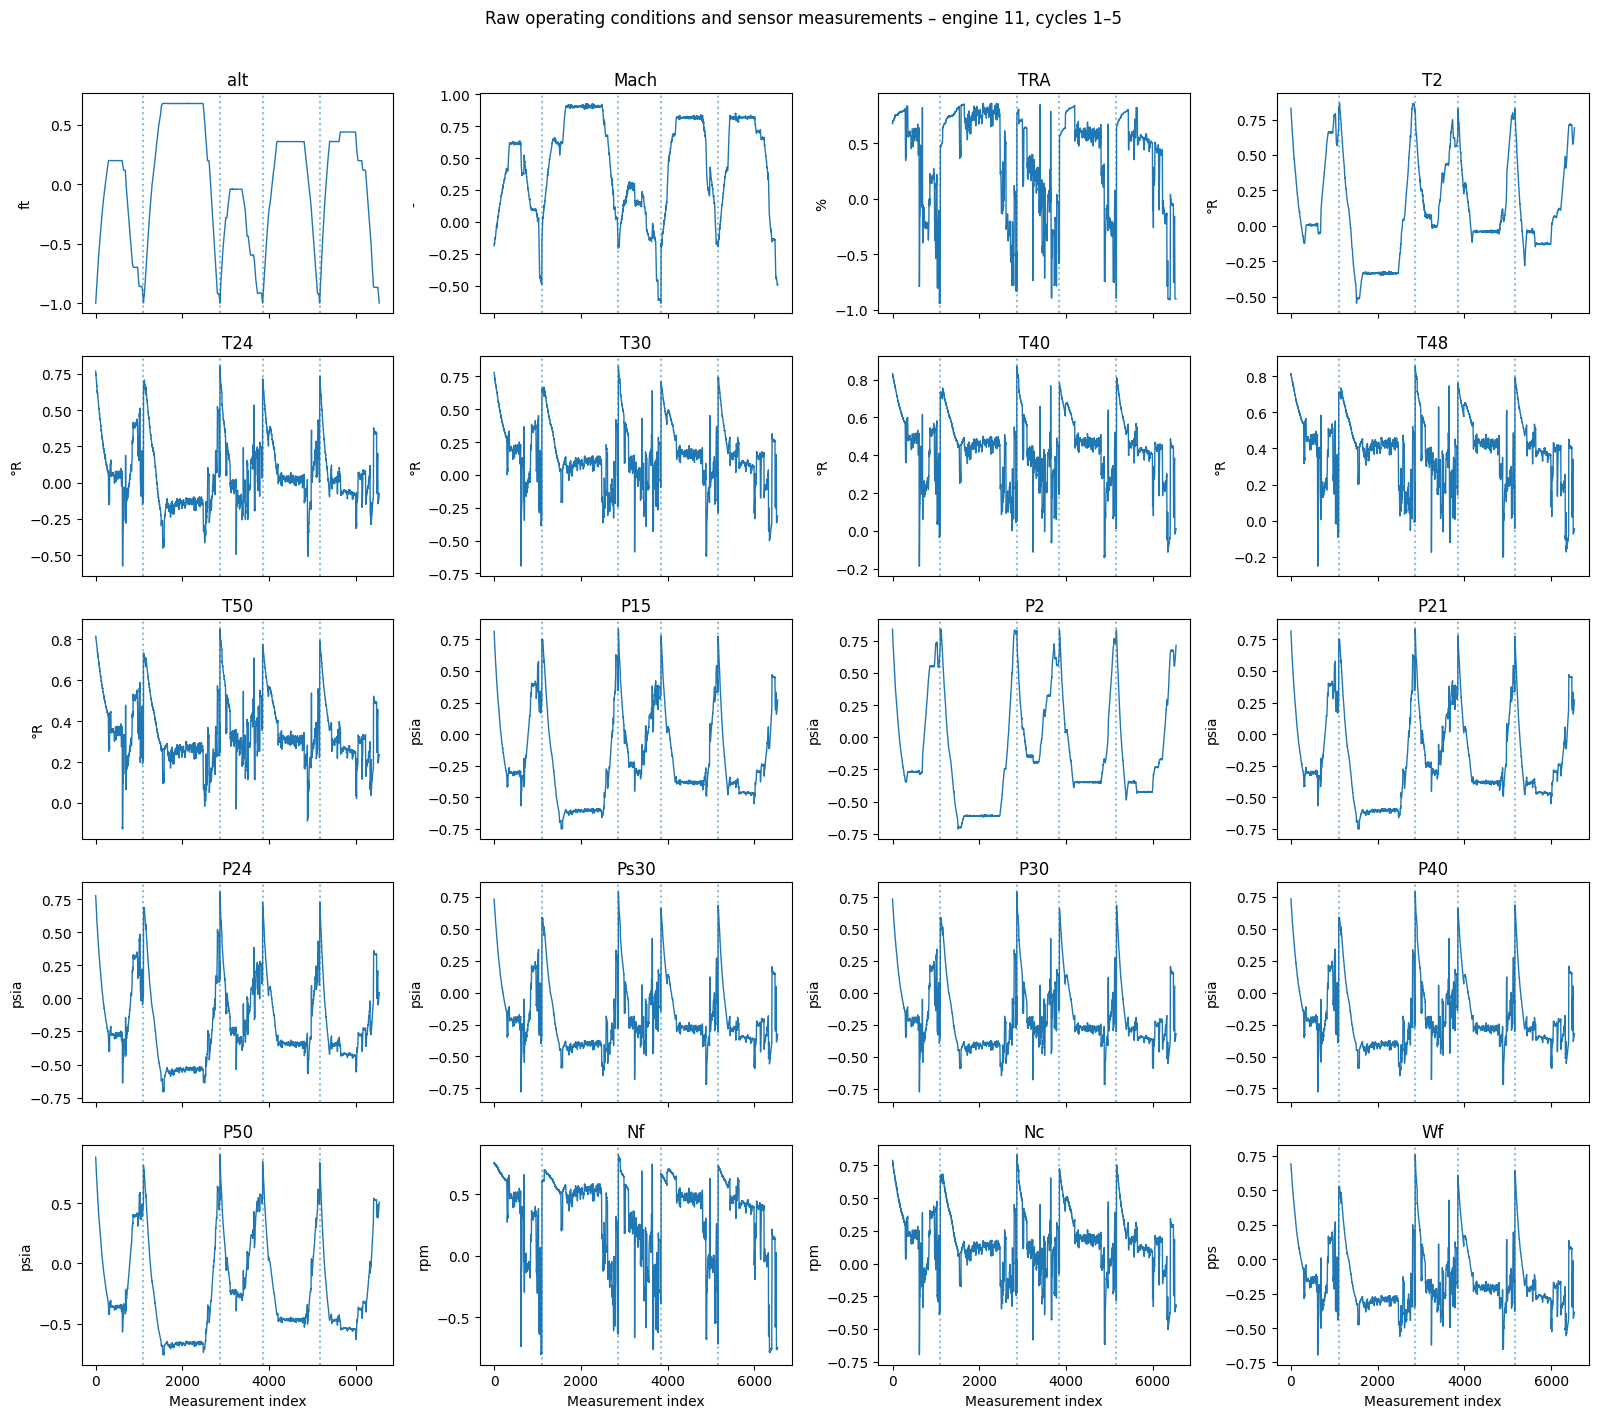

In [ ]:
fig, axes = plt.subplots(
    5,
    4,
    figsize=(16, 14),
    sharex=True,
)

axes = axes.ravel()

cycle_starts = raw_subset.groupby("cycle").head(1).index

for i, variable in enumerate(feature_names):
    axes[i].plot(
        raw_subset.index,
        raw_subset[variable],
        linewidth=1,
    )

    axes[i].set_title(variable)
    axes[i].set_ylabel(feature_units[variable])

    for cycle_start in cycle_starts[1:]:
        axes[i].axvline(
            cycle_start,
            linestyle=":",
            alpha=0.5,
        )

for ax in axes[-4:]:
    ax.set_xlabel("Measurement index")

plt.suptitle(
    f"Raw operating conditions and sensor measurements – "
    f"engine {unit_to_plot}, cycles "
    f"{cycles_to_plot[0]}–{cycles_to_plot[-1]}",
    y=1.01,
)

plt.tight_layout()
plt.show()

### What can we observe?

The raw variables do not change only because of degradation. They also vary substantially within and between flight cycles.

In particular:

- the operating conditions change during a flight cycle;
- temperatures, pressures and rotational speeds respond to these changes;
- some variables vary smoothly, while others change more abruptly;
- the variables have very different numerical scales;
- many sensor responses appear to change together.

This makes it difficult to identify degradation using a fixed threshold on one raw variable.

## compare early with late cycles

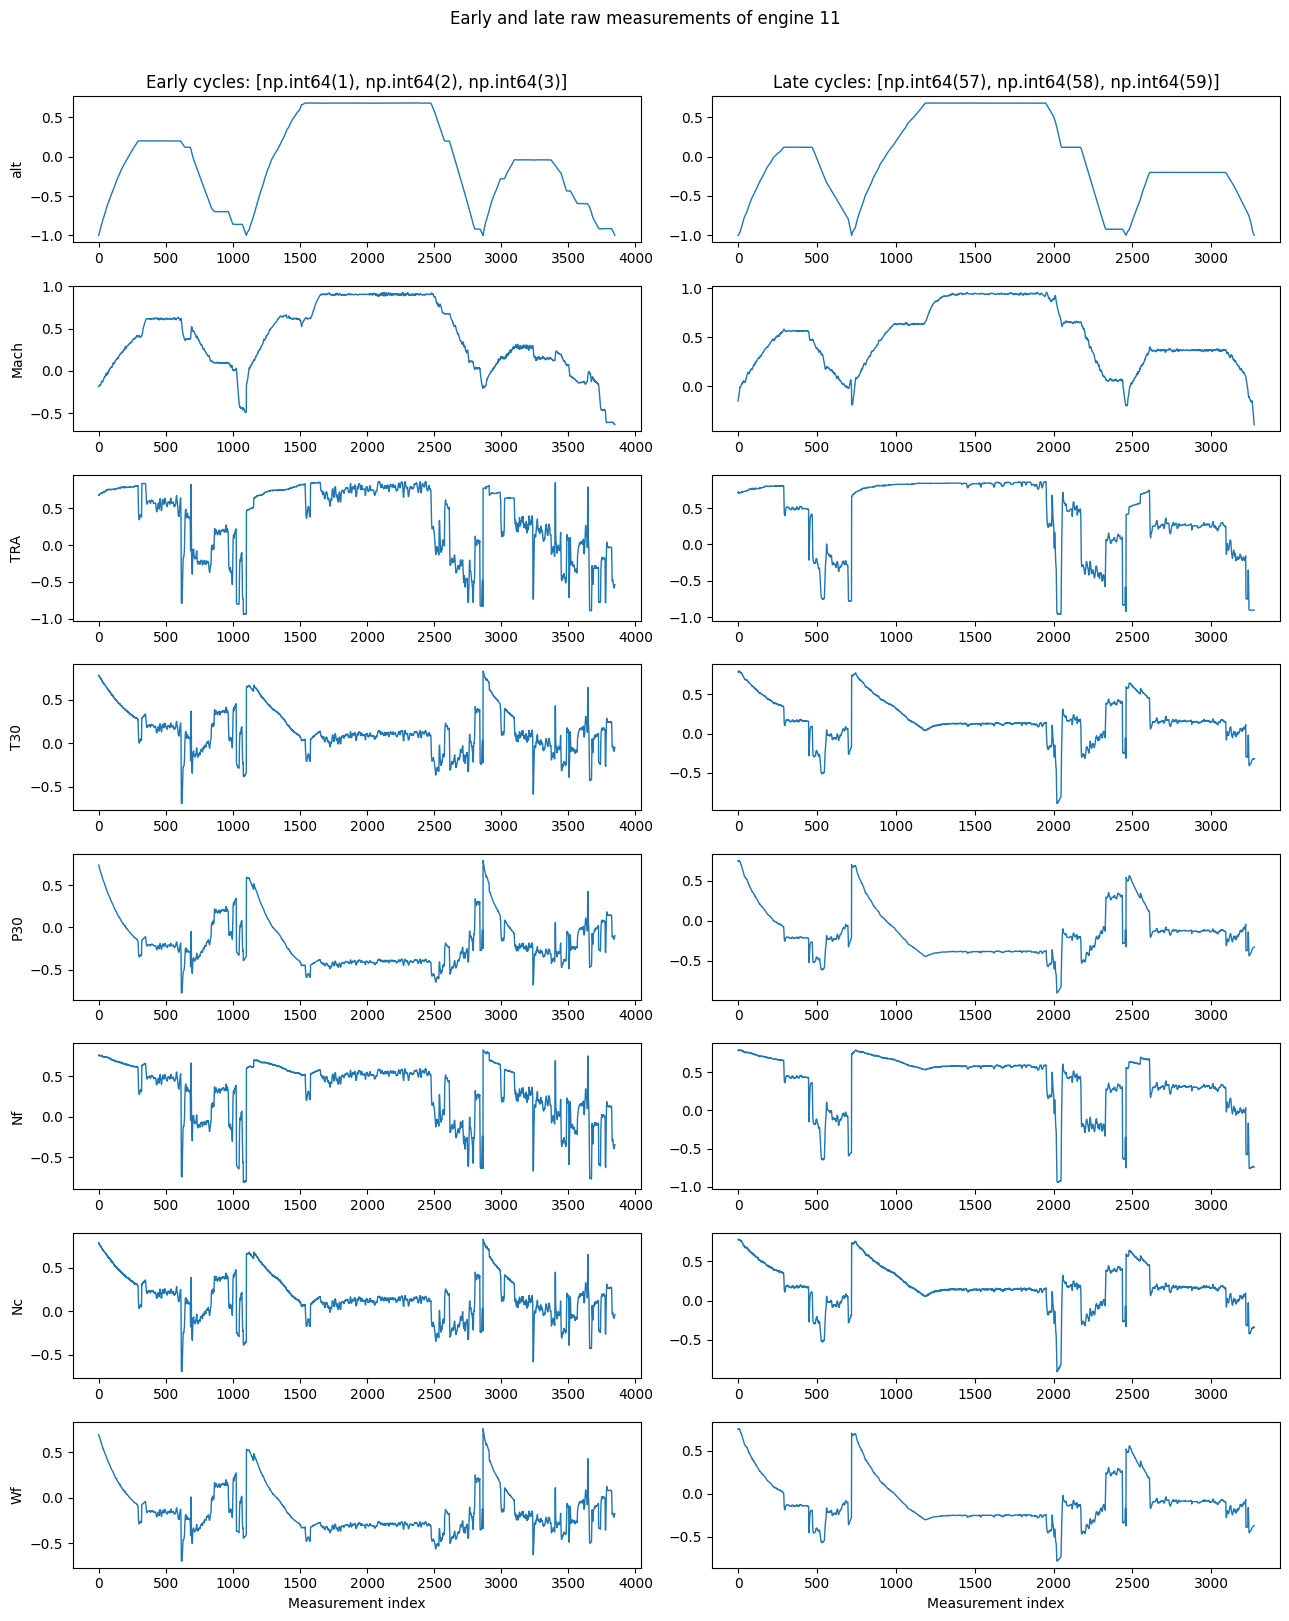

In [ ]:
unit_to_plot = 11

unit_data = test_raw[
    test_raw["unit"] == unit_to_plot
].copy()

available_cycles = np.sort(unit_data["cycle"].unique())

early_cycles = available_cycles[:3]
late_cycles = available_cycles[-3:]

selected_variables = [
    "alt",
    "Mach",
    "TRA",
    "T30",
    "P30",
    "Nf",
    "Nc",
    "Wf",
]

fig, axes = plt.subplots(
    len(selected_variables),
    2,
    figsize=(13, 16),
)

for row, variable in enumerate(selected_variables):

    early_data = unit_data[
        unit_data["cycle"].isin(early_cycles)
    ].reset_index(drop=True)

    late_data = unit_data[
        unit_data["cycle"].isin(late_cycles)
    ].reset_index(drop=True)

    axes[row, 0].plot(
        early_data.index,
        early_data[variable],
        linewidth=1,
    )

    axes[row, 1].plot(
        late_data.index,
        late_data[variable],
        linewidth=1,
    )

    axes[row, 0].set_ylabel(variable)

    if row == 0:
        axes[row, 0].set_title(
            f"Early cycles: {list(early_cycles)}"
        )
        axes[row, 1].set_title(
            f"Late cycles: {list(late_cycles)}"
        )

axes[-1, 0].set_xlabel("Measurement index")
axes[-1, 1].set_xlabel("Measurement index")

plt.suptitle(
    f"Early and late raw measurements of engine {unit_to_plot}",
    y=1.01,
)

plt.tight_layout()
plt.show()

## Think

Compare the early and late flight cycles.

- Do the operating conditions cover exactly the same ranges?
- Do any sensor variables appear to shift as the engine degrades?
- Can a change in a sensor be attributed directly to degradation?
- Why is it difficult to compare the early and late measurements without accounting for the operating conditions?

## Pairplot

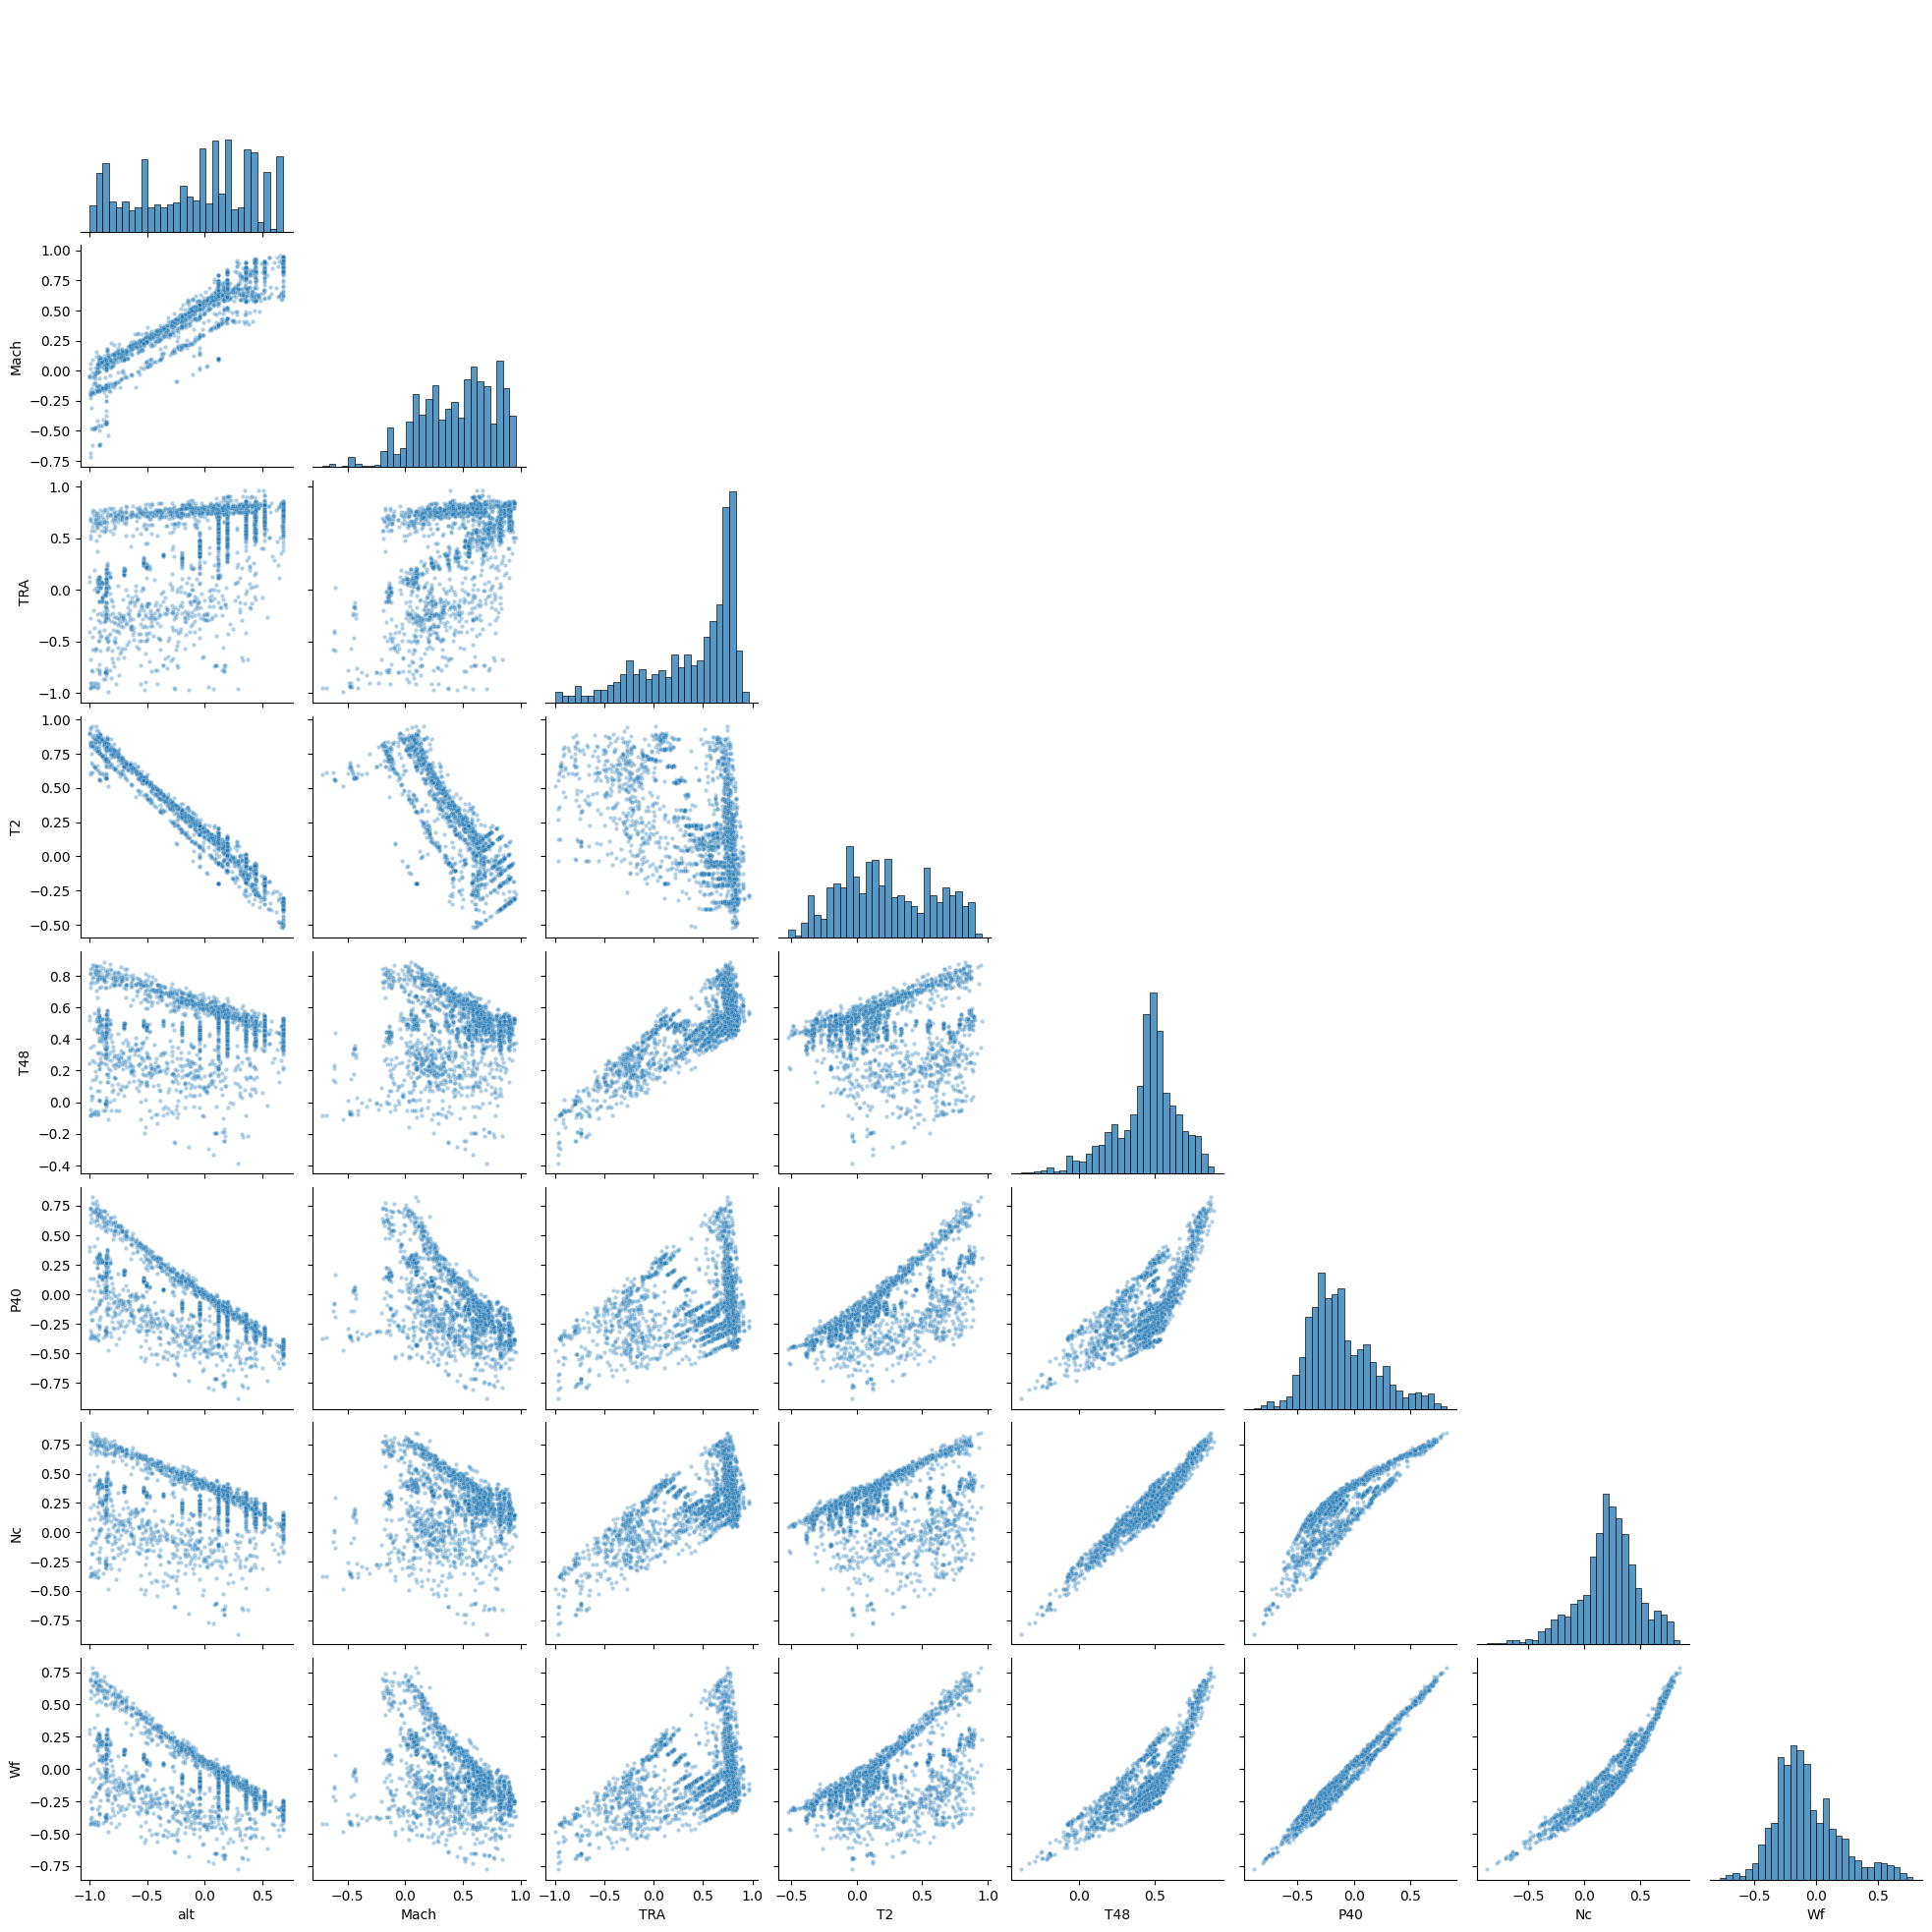

In [ ]:
import seaborn as sns

pairplot_variables = [
    "alt",
    "Mach",
    "TRA",
    "T2",
    "T48",
    "P40",
    "Nc",
    "Wf",
]

pairplot_data = test_raw[
    test_raw["unit"] == 11
][pairplot_variables].copy()

# A pairplot of all measurements would be slow and visually dense.
# A random sample is sufficient for exploring the relationships.
pairplot_data = pairplot_data.sample(
    n=min(2000, len(pairplot_data)),
    random_state=42,
)

sns.pairplot(
    pairplot_data,
    corner=True,
    plot_kws={
        "s": 10,
        "alpha": 0.35,
    },
    diag_kws={
        "bins": 30,
    },
)

plt.show()

The pairplot shows that many variables are strongly related.

Some relationships arise because several sensors respond to the same operating conditions. For example, changing the throttle setting can simultaneously affect temperatures, pressures, rotational speeds and fuel flow.

The data therefore do not form one simple cluster. Instead, healthy measurements occupy a structured region determined partly by the operating conditions.

A multivariate anomaly detection method should learn these relationships rather than evaluate every variable independently.

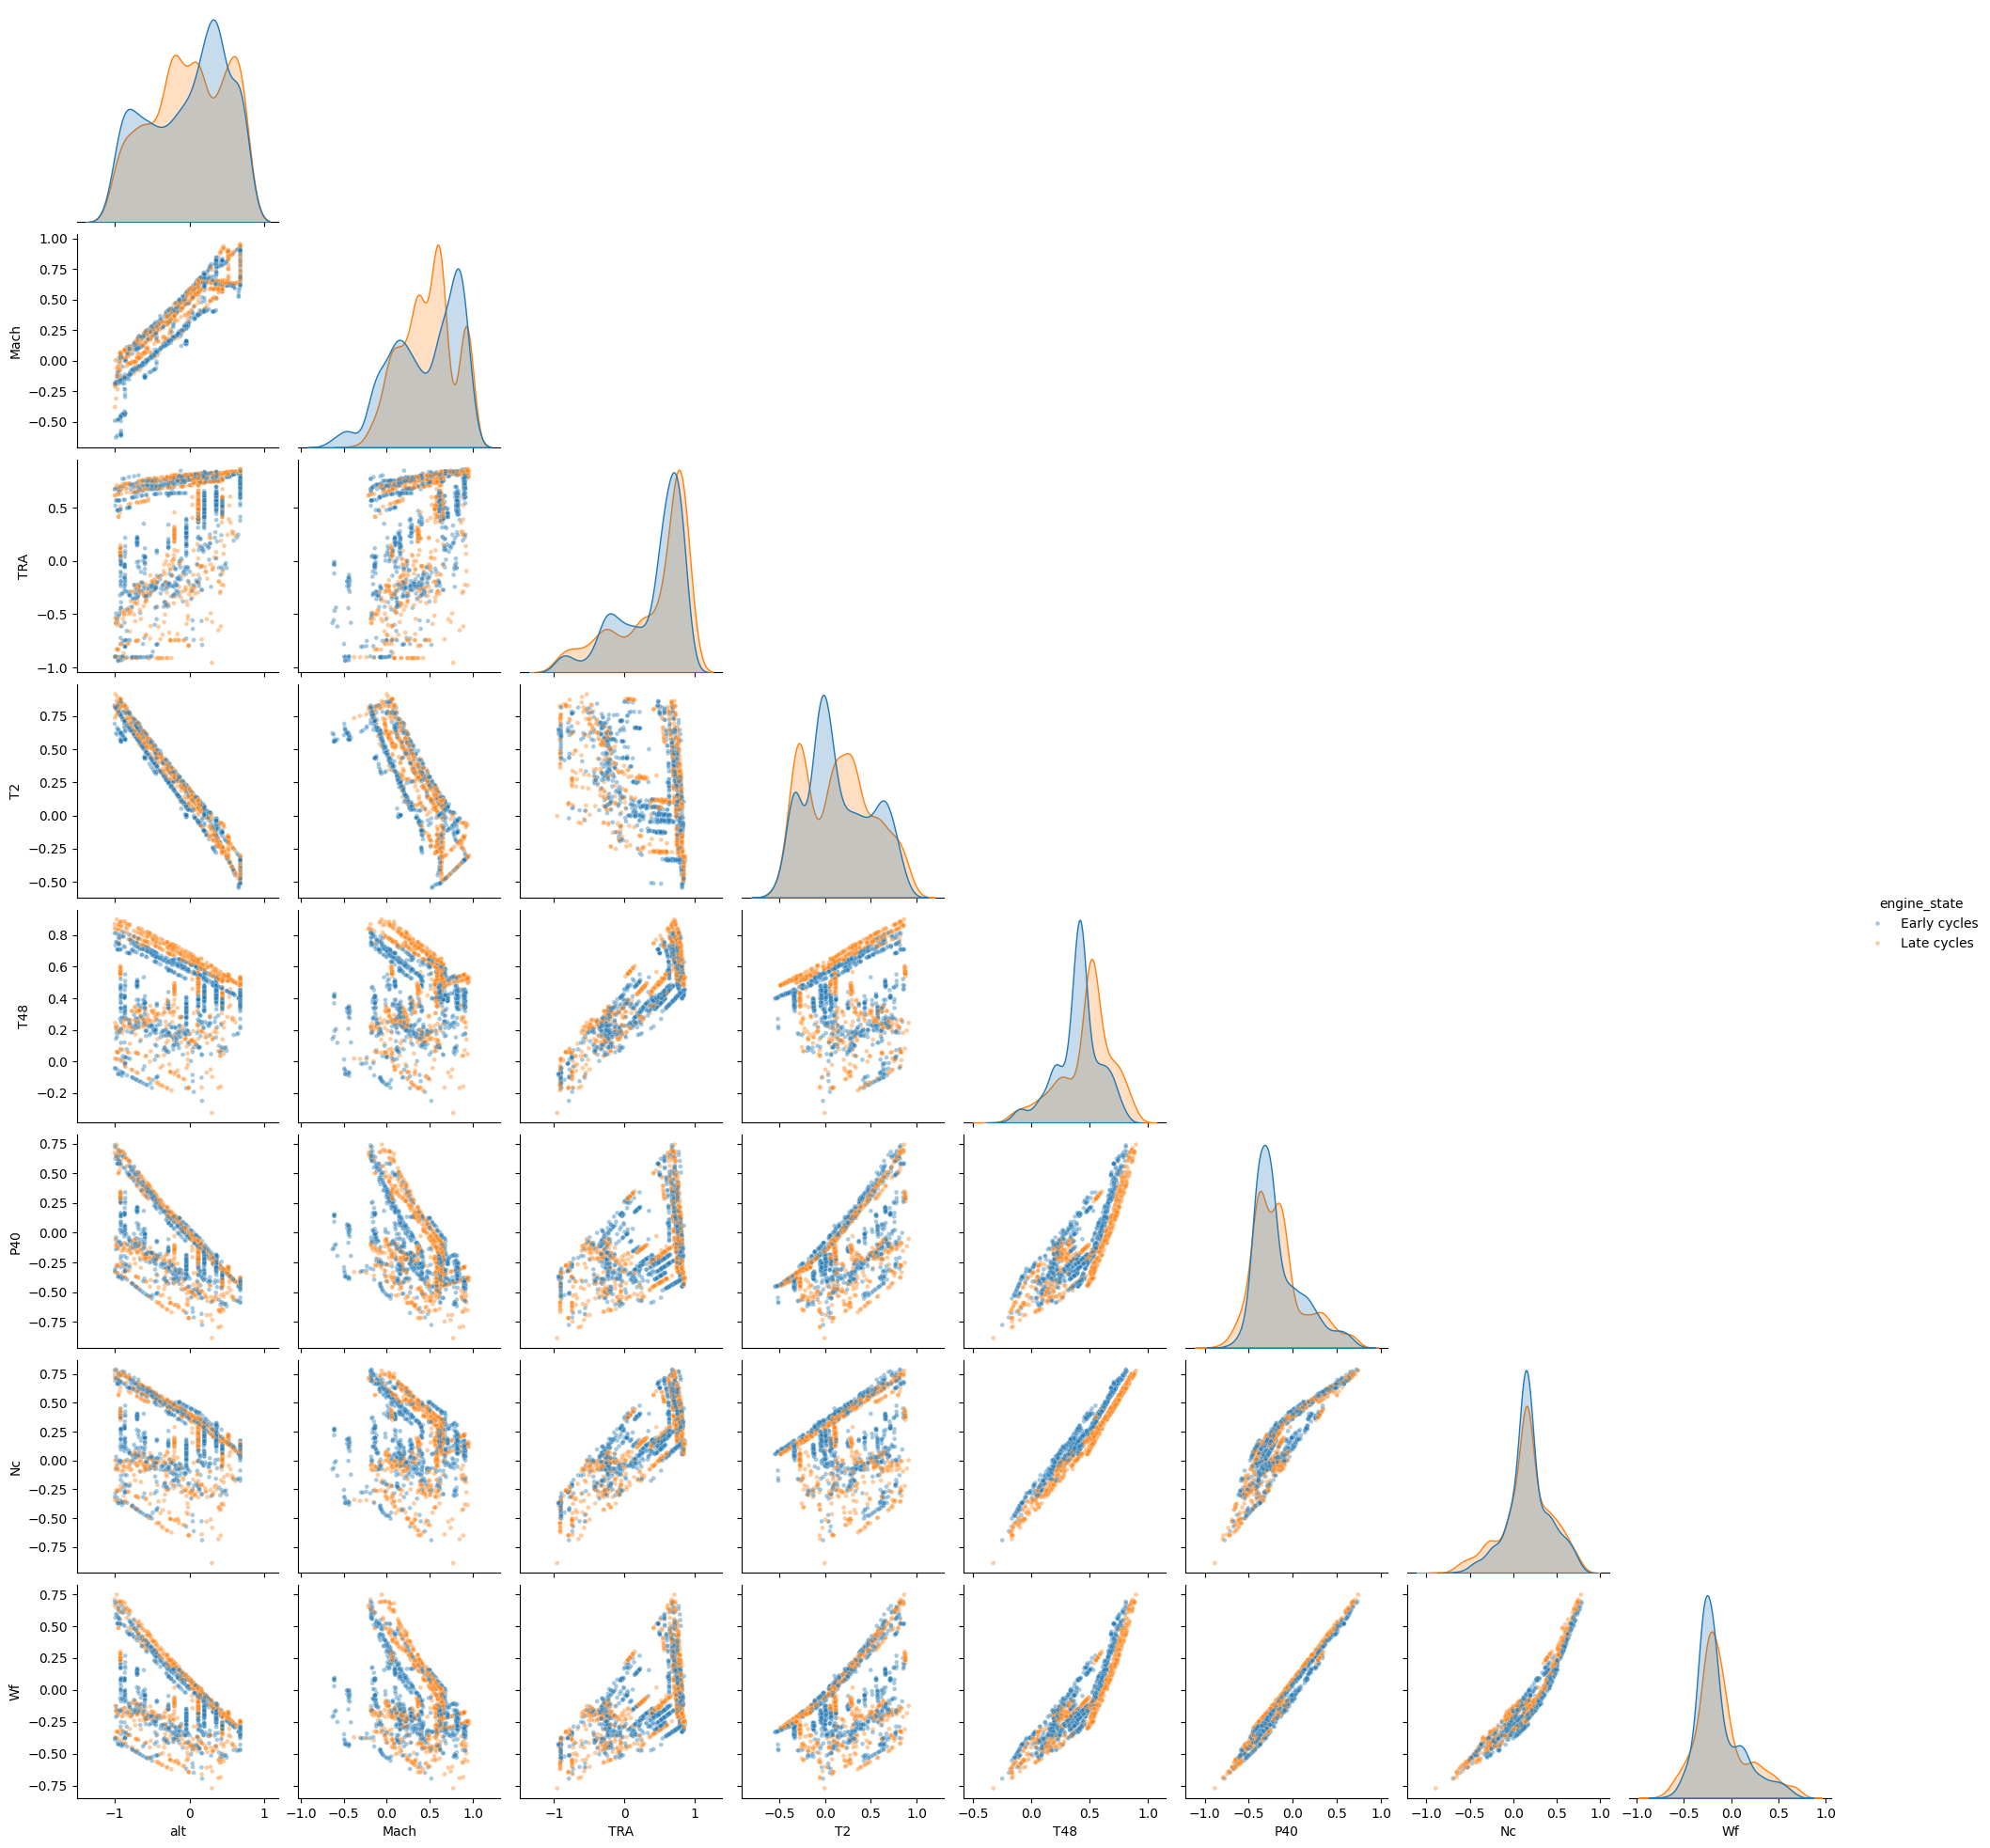

In [ ]:
pairplot_data = test_raw[
    test_raw["unit"] == 11
][
    ["cycle"] + pairplot_variables
].copy()

last_cycle = pairplot_data["cycle"].max()

pairplot_data["engine_state"] = np.where(
    pairplot_data["cycle"] <= 5,
    "Early cycles",
    np.where(
        pairplot_data["cycle"] >= last_cycle - 4,
        "Late cycles",
        "Not selected",
    ),
)

pairplot_data = pairplot_data[
    pairplot_data["engine_state"] != "Not selected"
]

pairplot_data = pairplot_data.sample(
    n=min(2000, len(pairplot_data)),
    random_state=42,
)

sns.pairplot(
    pairplot_data,
    vars=pairplot_variables,
    hue="engine_state",
    corner=True,
    plot_kws={
        "s": 12,
        "alpha": 0.4,
    },
    diag_kws={
        "common_norm": False,
    },
)

plt.show()

## 2. Inspect the degradation trajectories

The exact fault state is not directly observed from a single raw sensor. Nevertheless, several sensor responses change as an engine approaches failure.

The following plot shows cycle-averaged values for three selected sensors. Cycle averaging reduces the fast variation within each flight cycle and makes the slow degradation trend easier to see.

In [ ]:
def cycle_mean(values, units, cycles):
    """Return one mean value per engine and flight cycle."""
    rows = []

    for unit in np.unique(units):
        unit_mask = units == unit

        for cycle in np.unique(cycles[unit_mask]):
            mask = unit_mask & (cycles == cycle)
            rows.append([unit, cycle, *values[mask].mean(axis=0)])

    columns = ["unit", "cycle"] + [f"x{i}" for i in range(values.shape[1])]
    return pd.DataFrame(rows, columns=columns)

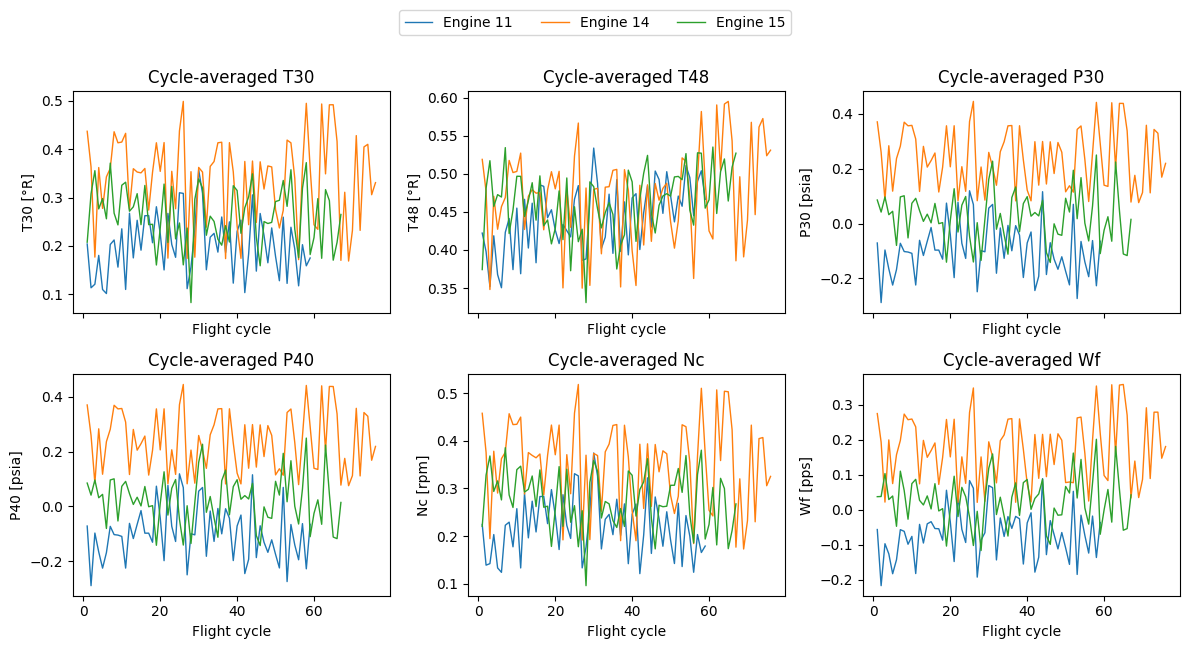

In [ ]:
selected_sensor_names = [
    "T30",
    "T48",
    "P30",
    "P40",
    "Nc",
    "Wf",
]

selected_sensor_idx = [
    Xs_names.index(name)
    for name in selected_sensor_names
]

sensor_cycle_means = cycle_mean(
    Xs_test[:, selected_sensor_idx],
    U_test,
    C_test,
)

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(12, 6),
    sharex=True,
)

axes = axes.ravel()

for j, sensor in enumerate(selected_sensor_names):
    ax = axes[j]

    for unit in np.unique(sensor_cycle_means["unit"]):
        subset = sensor_cycle_means[
            sensor_cycle_means["unit"] == unit
        ]

        ax.plot(
            subset["cycle"],
            subset[f"x{j}"],
            label=f"Engine {int(unit)}",
            linewidth=1,
        )

    ax.set_xlabel("Flight cycle")
    ax.set_ylabel(f"{sensor} [{feature_units[sensor]}]")
    ax.set_title(f"Cycle-averaged {sensor}")

# One shared legend instead of repeating it in every subplot
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=len(labels),
    bbox_to_anchor=(0.5, 1.02),
)

plt.tight_layout()
plt.show()

## Think

- Do all engines follow the same trajectory?
- Can one fixed threshold on a raw sensor reliably detect degradation?
- Why might the operating conditions influence the sensor values?

## 3. Preprocess the data

We use development engines 16, 18, and 20.

Only measurements from their first 20 cycles are treated as healthy and used for model development. This is an assumption supplied by the dataset description, not something inferred by the anomaly detector.

The operating conditions and sensor measurements have very different numerical ranges. We therefore scale every variable to the interval `[0, 1]`.

**Important:** the scaler is fitted only on healthy development data. Using degraded test data to determine the scaling would leak information from the test set into the model.

In [ ]:
development_units = [16, 18, 20]
healthy_cycle_limit = 20

development_mask = np.isin(U_dev, development_units)
healthy_mask = development_mask & (C_dev <= healthy_cycle_limit)

X_healthy_raw = np.concatenate(
    [W_dev[healthy_mask], Xs_dev[healthy_mask]],
    axis=1,
)

U_healthy = U_dev[healthy_mask]
C_healthy = C_dev[healthy_mask]

X_test_raw = np.concatenate(
    [W_test, Xs_test],
    axis=1,
)

scaler = MinMaxScaler()
X_healthy = scaler.fit_transform(X_healthy_raw)
X_test = scaler.transform(X_test_raw)

(
    X_train,
    X_val,
    U_train,
    U_val,
    C_train,
    C_val,
) = train_test_split(
    X_healthy,
    U_healthy,
    C_healthy,
    test_size=0.10,
    random_state=42,
    shuffle=True,
)

### Labels for evaluation

The test engines begin to degrade at different flight cycles. These fault-onset values are used **only for evaluation**, not for training.

- label `0`: healthy
- label `1`: degraded

In [ ]:
fault_onset = {
    11: 19,
    14: 36,
    15: 24,
}

y_test_sample = np.array([
    int(cycle >= fault_onset[int(unit)])
    for unit, cycle in zip(U_test, C_test)
])

print("Fraction of degraded test samples:", y_test_sample.mean().round(3))

Fraction of degraded test samples: 0.655


# 4. PCA reconstruction model

In this notebook, PCA is applied to instantaneos measurement vectors. Consequently, the model learns correlations between the sensor variables at a single time instant but does not exploit temporal dependencies between consecutive measurements.

## Think

What do you expect when the number of principal components is increased?

- Will reconstruction of healthy data improve?
- Will anomaly detection necessarily improve?

In [ ]:
n_components = 5

pca = PCA(n_components=n_components)
pca.fit(X_train)

X_train_pca = pca.inverse_transform(pca.transform(X_train))
X_val_pca = pca.inverse_transform(pca.transform(X_val))
X_test_pca = pca.inverse_transform(pca.transform(X_test))

pca_train_error = np.mean((X_train - X_train_pca) ** 2, axis=1)
pca_val_error = np.mean((X_val - X_val_pca) ** 2, axis=1)
pca_test_error = np.mean((X_test - X_test_pca) ** 2, axis=1)

print("Explained variance:", round(pca.explained_variance_ratio_.sum(), 3))

Explained variance: 1.0


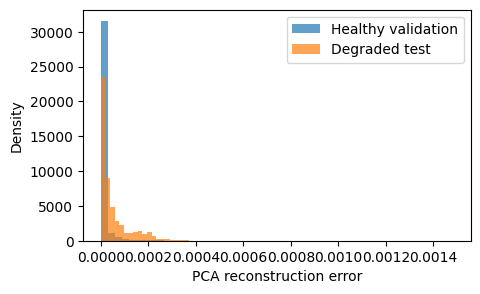

In [ ]:
plt.figure(figsize=(5, 3))
plt.hist(pca_val_error, bins=50, density=True, alpha=0.7, label="Healthy validation")
plt.hist(
    pca_test_error[y_test_sample == 1],
    bins=50,
    density=True,
    alpha=0.7,
    label="Degraded test",
)
plt.xlabel("PCA reconstruction error")
plt.ylabel("Density")
plt.legend()
plt.show()

## One anomaly score per engine cycle

The dataset contains many measurements within each flight cycle. Degradation evolves on a much slower time scale.

We therefore average the sample-wise reconstruction errors within each engine cycle. This gives one anomaly score per cycle.

In [ ]:
def aggregate_score_per_cycle(scores, units, cycles):
    """Average sample-wise scores within each engine cycle."""
    rows = []

    for unit in np.unique(units):
        unit_mask = units == unit

        for cycle in np.unique(cycles[unit_mask]):
            mask = unit_mask & (cycles == cycle)
            rows.append({
                "unit": int(unit),
                "cycle": int(cycle),
                "score": scores[mask].mean(),
            })

    return pd.DataFrame(rows)

pca_val_cycle = aggregate_score_per_cycle(
    pca_val_error,
    U_val,
    C_val,
)

pca_cycle = aggregate_score_per_cycle(
    pca_test_error,
    U_test,
    C_test,
)

pca_cycle["is_anomaly"] = [
    int(cycle >= fault_onset[unit])
    for unit, cycle in zip(
        pca_cycle["unit"],
        pca_cycle["cycle"],
    )
]
pca_cycle.head()

,unit,cycle,score,is_anomaly
0,11,1,0.000012,0
1,11,2,0.000006,0
2,11,3,0.000017,0
3,11,4,0.000007,0
4,11,5,0.000015,0


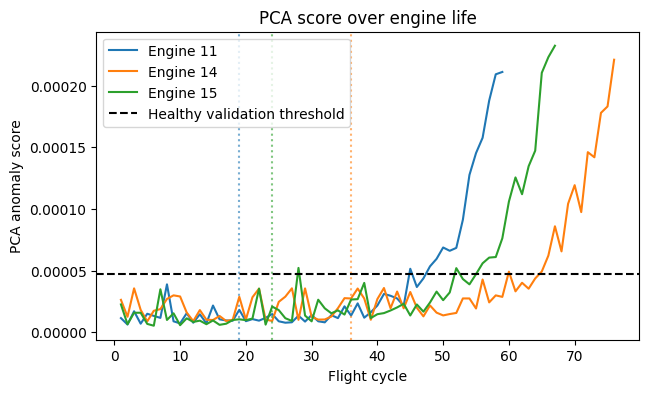

In [ ]:
pca_threshold = np.percentile(pca_val_cycle["score"], 99)

plt.figure(figsize=(7, 4))

for unit in pca_cycle["unit"].unique():
    subset = pca_cycle[pca_cycle["unit"] == unit]

    # Plot engine trajectory and capture its color
    line, = plt.plot(
        subset["cycle"],
        subset["score"],
        label=f"Engine {unit}",
    )

    plt.axvline(
        fault_onset[unit],
        color=line.get_color(),
        linestyle=":",
        alpha=0.6,
    )

plt.axhline(
    pca_threshold,
    linestyle="--",
    color="black",
    label="Healthy validation threshold",
)

plt.xlabel("Flight cycle")
plt.ylabel("PCA anomaly score")
plt.title("PCA score over engine life")
plt.legend()
plt.show()

The vertical dotted lines indicate the known onset of degradation. The horizontal dashed line is a possible decision threshold.

For gradual degradation, the continuous score is often more informative than the binary threshold decision. A health index can, for example, be defined as a decreasing transformation of this score.

## Think
- Are you happy with the results?
- How would you improve them?

# 5. Autoencoder reconstruction model

An autoencoder is a neural network trained to reconstruct its own input.

The bottleneck forces it to learn a compressed representation of the combinations of variables that occur during healthy operation.

In [ ]:
n_features = X_train.shape[1]
latent_dim = 5

autoencoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(n_features,)),
    tf.keras.layers.Dense(12, activation="relu"),
    tf.keras.layers.Dense(latent_dim, activation="relu"),
    tf.keras.layers.Dense(12, activation="relu"),
    tf.keras.layers.Dense(n_features),
])

autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           252 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 12)             │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 649 (2.54 KB)

 Trainable params: 649 (2.54 KB)

 Non-trainable params: 0 (0.00 B)

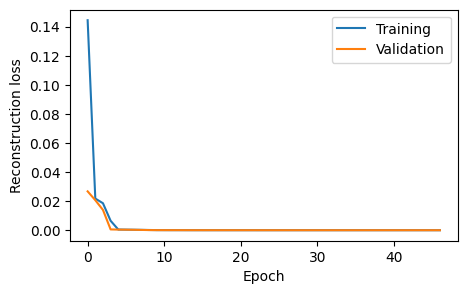

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
)

history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=0,
)

plt.figure(figsize=(5, 3))
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction loss")
plt.legend()
plt.show()

In [ ]:
X_train_ae = autoencoder.predict(X_train, verbose=0)
X_val_ae = autoencoder.predict(X_val, verbose=0)
X_test_ae = autoencoder.predict(X_test, verbose=0)

ae_train_error = np.mean((X_train - X_train_ae) ** 2, axis=1)
ae_val_error = np.mean((X_val - X_val_ae) ** 2, axis=1)
ae_test_error = np.mean((X_test - X_test_ae) ** 2, axis=1)

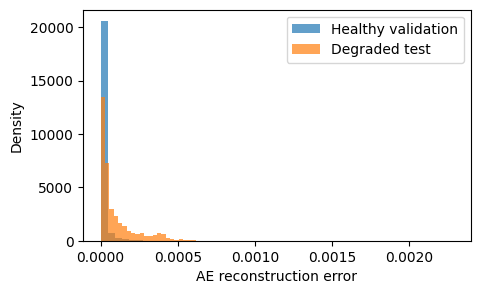

In [ ]:
plt.figure(figsize=(5, 3))
plt.hist(ae_val_error, bins=50, density=True, alpha=0.7, label="Healthy validation")
plt.hist(
    ae_test_error[y_test_sample == 1],
    bins=50,
    density=True,
    alpha=0.7,
    label="Degraded test",
)
plt.xlabel("AE reconstruction error")
plt.ylabel("Density")
plt.legend()
plt.show()

In [ ]:
ae_val_cycle = aggregate_score_per_cycle(
    ae_val_error,
    U_val,
    C_val,
)

ae_cycle = aggregate_score_per_cycle(
    ae_test_error,
    U_test,
    C_test,
)

ae_cycle["is_anomaly"] = [
    int(cycle >= fault_onset[unit])
    for unit, cycle in zip(
        ae_cycle["unit"],
        ae_cycle["cycle"],
    )
]

ae_threshold = np.percentile(
    ae_val_cycle["score"],
    99,
)

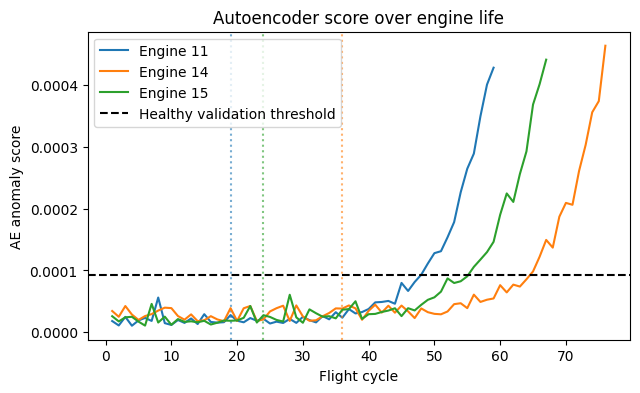

In [ ]:


plt.figure(figsize=(7, 4))

for unit in ae_cycle["unit"].unique():
    subset = ae_cycle[ae_cycle["unit"] == unit]
    # Plot engine trajectory and capture its color
    line, = plt.plot(
        subset["cycle"],
        subset["score"],
        label=f"Engine {unit}",
    )

    plt.axvline(
        fault_onset[unit],
        color=line.get_color(),
        linestyle=":",
        alpha=0.6,
    )

plt.axhline(
    ae_threshold,
    linestyle="--",
    color="black",
    label="Healthy validation threshold",
)
plt.xlabel("Flight cycle")
plt.ylabel("AE anomaly score")
plt.title("Autoencoder score over engine life")
plt.legend()
plt.show()

## Think

- Does the anomaly score increase smoothly as the engine degrades?
- Does the model behave equally well for all three engines?
- What could explain differences between engines?

# 6. Compare PCA and the autoencoder

The precision-recall curve evaluates the ranking produced by the continuous anomaly score. It does not require us to choose one fixed threshold first.

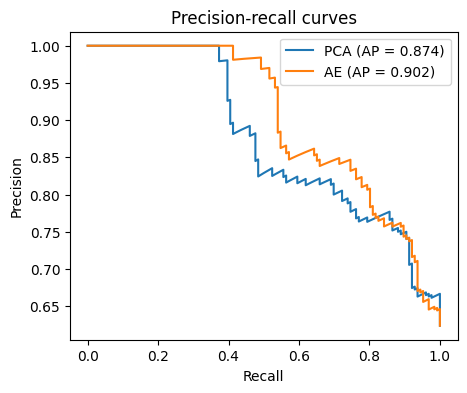

In [ ]:
y_true = pca_cycle["is_anomaly"].to_numpy()

pca_scores = pca_cycle["score"].to_numpy()
ae_scores = ae_cycle["score"].to_numpy()

pca_precision, pca_recall, _ = precision_recall_curve(y_true, pca_scores)
ae_precision, ae_recall, _ = precision_recall_curve(y_true, ae_scores)

pca_ap = average_precision_score(y_true, pca_scores)
ae_ap = average_precision_score(y_true, ae_scores)

plt.figure(figsize=(5, 4))
plt.plot(pca_recall, pca_precision, label=f"PCA (AP = {pca_ap:.3f})")
plt.plot(ae_recall, ae_precision, label=f"AE (AP = {ae_ap:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curves")
plt.legend()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Model": ["PCA", "Autoencoder"],
    "Average precision": [pca_ap, ae_ap],
    "Healthy validation mean error": [
        pca_val_error.mean(),
        ae_val_error.mean(),
    ],
})

comparison

,Model,Average precision,Healthy validation mean error
0,PCA,0.874328,0.000012
1,Autoencoder,0.901544,0.000019


## Think

- Which model gives the better anomaly ranking?
- Does the model with the lower healthy reconstruction error necessarily give the better anomaly detector?
- How could the PCA dimension or AE bottleneck dimension change the result?

# 7. What does the model tell us?

The total reconstruction error tells us whether the complete measurement vector is unusual. We can also inspect the reconstruction error of each variable.

In [ ]:
degraded_mask = y_test_sample == 1

variable_errors = pd.DataFrame({
    "Variable": feature_names,
    "Mean absolute reconstruction error": np.mean(
        np.abs(X_test[degraded_mask] - X_test_ae[degraded_mask]),
        axis=0,
    ),
}).sort_values(
    "Mean absolute reconstruction error",
    ascending=False,
)

variable_errors.head(10)

,Variable,Mean absolute reconstruction error
1,Mach,0.014769
8,T50,0.013862
7,T48,0.011726
0,alt,0.009660
17,Nf,0.008559
6,T40,0.007917
16,P50,0.007706
18,Nc,0.007092
2,TRA,0.006006
10,P2,0.005392


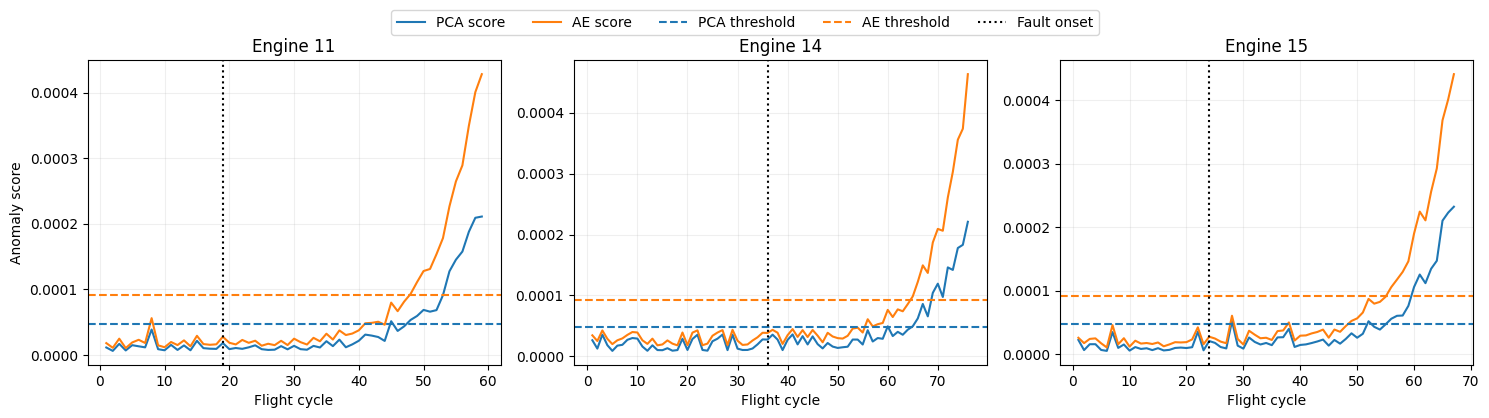

In [ ]:
pca_threshold = np.percentile(pca_val_cycle["score"], 99)
ae_threshold = np.percentile(ae_val_cycle["score"], 99)

units = sorted(pca_cycle["unit"].unique())

fig, axes = plt.subplots(
    1,
    len(units),
    figsize=(15, 4),
    sharey=False,
)

for ax, unit in zip(axes, units):

    pca_subset = (
        pca_cycle[pca_cycle["unit"] == unit]
        .sort_values("cycle")
    )

    ae_subset = (
        ae_cycle[ae_cycle["unit"] == unit]
        .sort_values("cycle")
    )

    # Plot scores and capture their colors
    pca_line, = ax.plot(
        pca_subset["cycle"],
        pca_subset["score"],
        label="PCA score",
    )

    ae_line, = ax.plot(
        ae_subset["cycle"],
        ae_subset["score"],
        label="AE score",
    )

    # Thresholds use the corresponding model colors
    ax.axhline(
        pca_threshold,
        color=pca_line.get_color(),
        linestyle="--",
        label="PCA threshold",
    )

    ax.axhline(
        ae_threshold,
        color=ae_line.get_color(),
        linestyle="--",
        label="AE threshold",
    )

    # Ground-truth onset
    ax.axvline(
        fault_onset[unit],
        color="black",
        linestyle=":",
        label="Fault onset",
    )

    ax.set_title(f"Engine {unit}")
    ax.set_xlabel("Flight cycle")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Anomaly score")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=5,
    bbox_to_anchor=(0.5, 1.05),
)

fig.tight_layout()
plt.show()

## Can you do better?
hint: don't try to change the model. Inspect the errors first.

## Optional detection schemes:
1. Mean reconstruction error (current).
2. Maximum normalized variable error (following).
3. Number of variables exceeding their thresholds (try).

## Final Think: reconstruction or regression?

A large reconstruction error for one variable does **not necessarily mean that this variable is the original source of the abnormality**.

In an autoencoder, every reconstructed output depends on the shared latent representation. An abnormal value in one variable can therefore affect the reconstruction of several other variables. This is sometimes called **error propagation between variables**.

Consider the physical structure of the system:

- operating conditions = inputs or commands
- sensor measurements = system responses

How could we formulate anomaly detection as a regression problem instead?

Would predicting each sensor response from the operating conditions make it easier to identify **which sensor no longer behaves as expected**?

## Plot signed reconstruction errors per variable
does it help isolate faults?

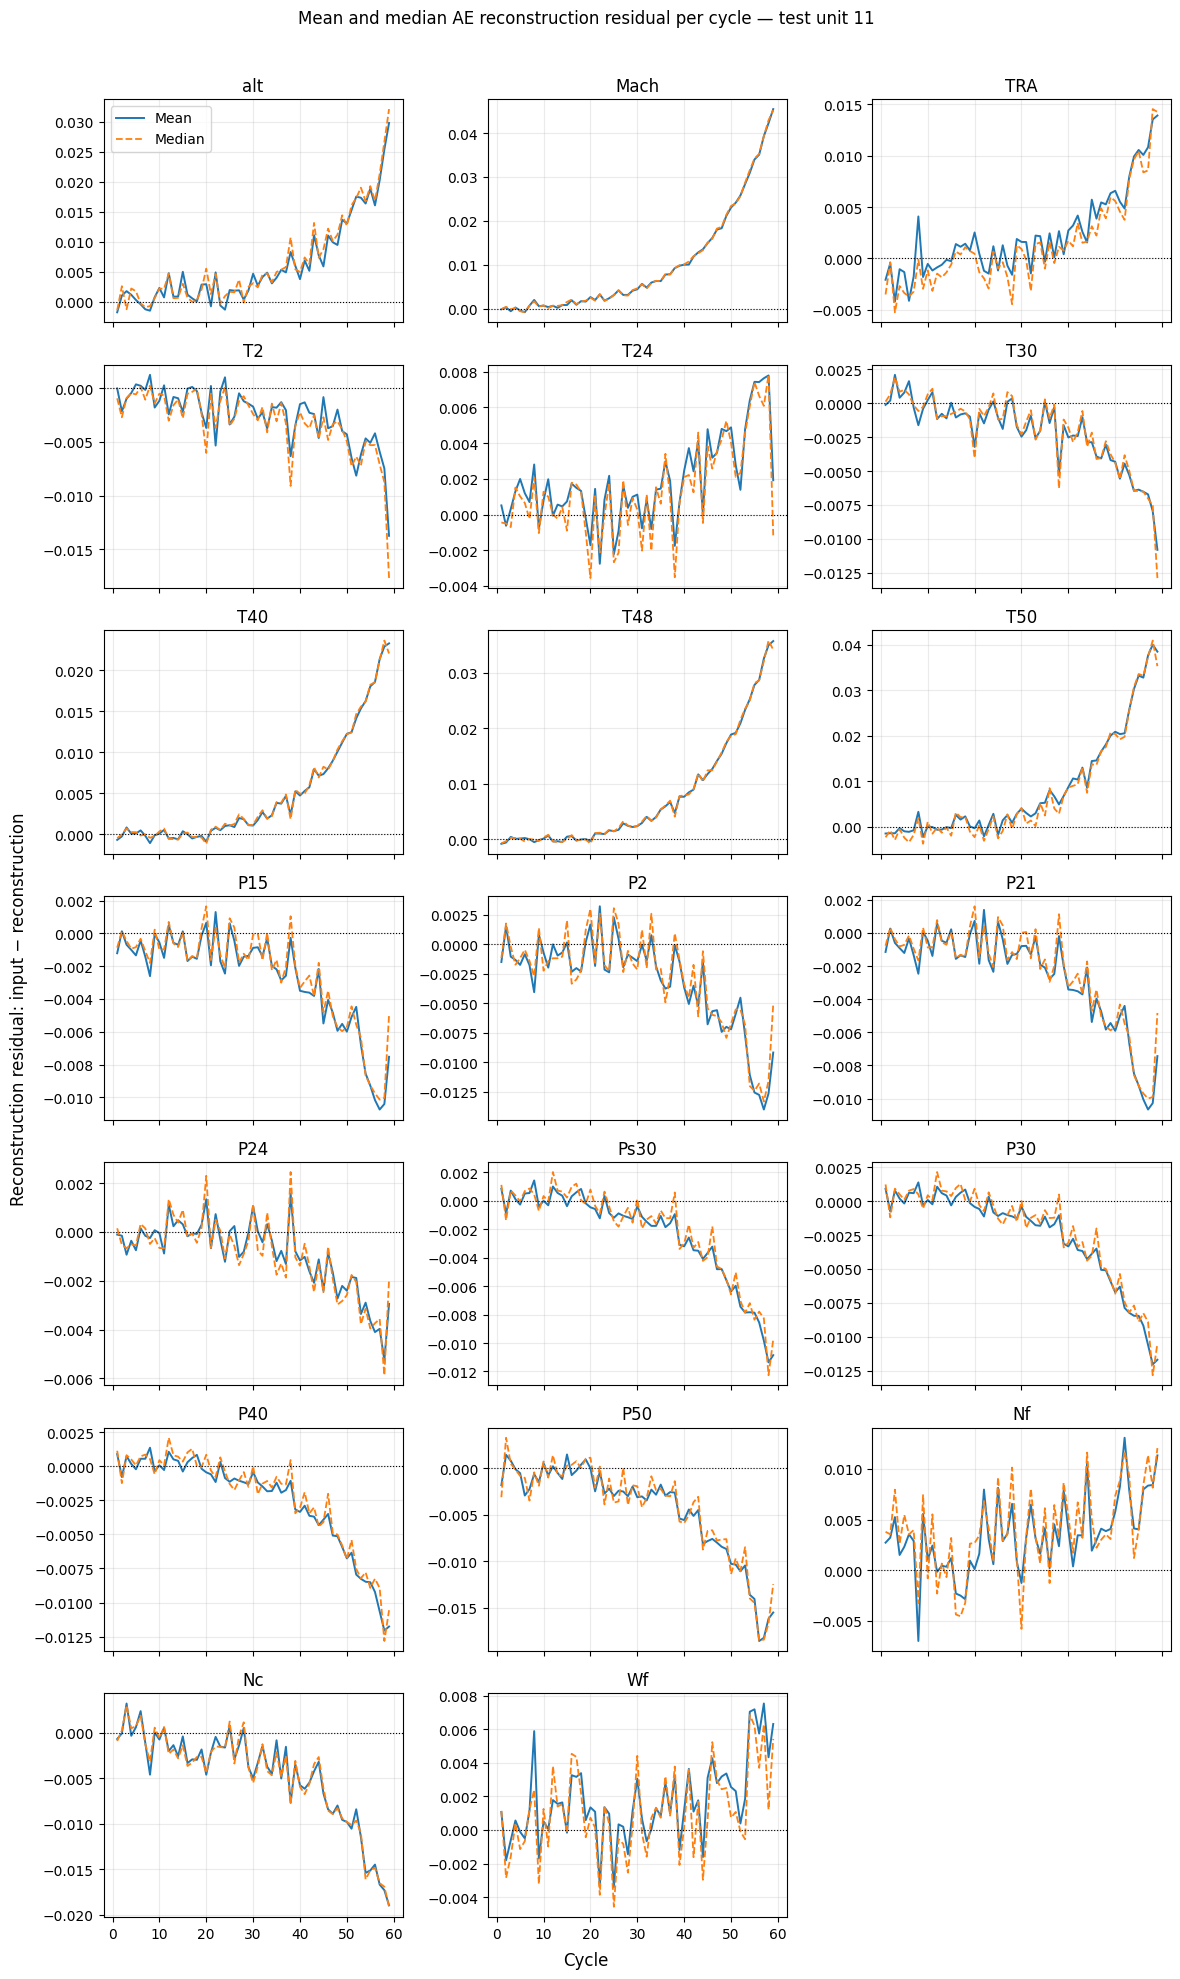

In [ ]:
import math
# Select one test unit
selected_unit = np.unique(U_test)[0]

# All samples and all cycles belonging to this unit
unit_mask = U_test == selected_unit

cycles_unit = C_test[unit_mask]

# Signed AE reconstruction residuals
residuals_unit = (
    X_test[unit_mask]
    - X_test_ae[unit_mask]
)

cycle_values = np.sort(np.unique(cycles_unit))

# Aggregate each reconstructed variable within each cycle
mean_residuals_ae = np.vstack([
    residuals_unit[cycles_unit == cycle].mean(axis=0)
    for cycle in cycle_values
])

median_residuals_ae = np.vstack([
    np.median(
        residuals_unit[cycles_unit == cycle],
        axis=0,
    )
    for cycle in cycle_values
])

output_names = feature_names
n_outputs = len(output_names)

n_cols = 3
n_rows = math.ceil(n_outputs / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 2.8 * n_rows),
    sharex=True,
)

axes = np.asarray(axes).ravel()

for j, variable_name in enumerate(output_names):
    ax = axes[j]

    ax.plot(
        cycle_values,
        mean_residuals_ae[:, j],
        label="Mean",
        linewidth=1.4,
    )

    ax.plot(
        cycle_values,
        median_residuals_ae[:, j],
        label="Median",
        linestyle="--",
        linewidth=1.3,
    )

    ax.axhline(
        0,
        color="k",
        linestyle=":",
        linewidth=0.8,
    )

    ax.set_title(variable_name)
    ax.grid(alpha=0.25)

for ax in axes[n_outputs:]:
    ax.remove()

axes[0].legend()

fig.suptitle(
    f"Mean and median AE reconstruction residual per cycle — "
    f"test unit {int(selected_unit)}",
    y=1.01,
)

fig.supxlabel("Cycle")
fig.supylabel("Reconstruction residual: input − reconstruction")
fig.tight_layout()
plt.show()